# NUFFT vs ducc0 gridder check 
This plot shows the synthetic sky image used to validate the correctness of Fourier transform methods.

- The image is typically a 2D Gaussian distribution.
- It serves as the input to both:
  - **NUFFT (Non-uniform Fast Fourier Transform)** via `finufft`
  - **dirty2vis** gridding via `ducc0`

The accuracy of the visibility computation is verified by comparing the transforms from both methods.

**Inputs**:
- `I`: 2D NumPy array of sky brightness intensity
- `fov_mas`: Field of view in milliarcseconds (for axis labels)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from finufft import nufft2d2
import ducc0.wgridder as ng 
import sys 
import nifty8 as ift

### Create test image 

In [2]:
speedoflight = 299792458.0
lam = 1.1e-6  
# Parameters
npix    = 256
fov_mas = 30  # field of view in milliarcseconds
fov_rad = fov_mas * np.pi / (180 * 3600 * 1000)  # convert to radians
dx      = fov_rad / npix  # angular pixel size in radians

# Sky coordinates (l, m)
x = (np.arange(npix) - npix//2) * dx
y = (np.arange(npix) - npix//2) * dx
X,Y = np.meshgrid(x, y, indexing='ij')

# Sky image: 2D Gaussian
sigma = fov_rad / 10
I     = np.exp(-(X**2 + Y**2)/(2 * sigma**2))

# Simulate random (u,v) coords in meters and convert to wavelengths
num = 64
u1  = np.linspace(-50, 50, num)  
v1  = np.linspace(-50, 50, num)
U2,V2 = np.meshgrid(u1, v1, indexing='ij')
U = U2.flatten()
V = V2.flatten() 

baseline_length = np.sqrt(u1**2 + v1**2)

# NUFFT expects (x, y) = (2π*u*dx, 2π*v*dx)
kx  = 2 * np.pi * U/lam * dx
ky  = 2 * np.pi * V/lam * dx
kx1 = 2 * np.pi * u1/lam * dx
ky1 = 2 * np.pi * v1/lam * dx

# Compute visibilities using NUFFT (type 2: non-uniform points from uniform image)
vis_nfft_1D = nufft2d2(kx1, ky1, I.astype(np.complex128), eps=1e-9)
vis_nfft    = nufft2d2(kx, ky, I.astype(np.complex128), eps=1e-9)
vis_nfft    = vis_nfft.reshape(num, num)
vis_nfft_1D = vis_nfft_1D/np.max(np.abs(vis_nfft_1D))

In [3]:
def plot_sky_distribution(I, fov_mas):
    """
    Plot the sky brightness distribution as a 2D image.

    Parameters
    ----------
    I : ndarray
        2D array representing the sky brightness intensity (image).
    fov_mas : float
        Field of view in milliarcseconds for axis labeling.

    Returns
    -------
    None
    """
    extent = [-fov_mas/2, fov_mas/2, -fov_mas/2, fov_mas/2]
    plt.figure(figsize=(5, 4))
    plt.imshow(I, origin='lower', extent=extent, cmap='inferno')
    plt.colorbar(label="Intensity")
    plt.xlabel("RA offset (mas)")
    plt.ylabel("Dec offset (mas)")
    plt.title("Sky Brightness Distribution")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

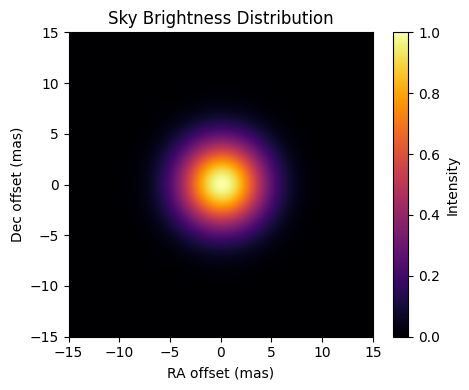

In [4]:
plot_sky_distribution(I, fov_mas)

In [5]:
uvw     = np.stack([U.flatten(), V.flatten(), np.zeros(num*num)], axis=1)
uvw_1D  = np.stack([u1, v1, np.zeros(num)], axis=1)
freq    = np.array([speedoflight / lam]) 
vis_d2v_1D = ng.dirty2vis(uvw=uvw_1D,freq=freq, dirty=np.real(I), pixsize_x=dx, pixsize_y=dx, epsilon=1e-9, do_wgridding=False)
vis_d2v    = ng.dirty2vis(uvw=uvw,freq=freq, dirty=np.real(I), pixsize_x=dx, pixsize_y=dx, epsilon=1e-9, do_wgridding=False)
vis_d2v    = vis_d2v.reshape(num, num)   
vis_d2v_1D = vis_d2v_1D/np.max(np.abs(vis_d2v_1D))

### Plot: NUFFT vs Dirty2Vis Comparison
This function compares the amplitude of the visibilities computed using NUFFT and `dirty2vis`.
It displays three subplots:
- **NFFT Amplitude:** Log-scaled amplitude of NUFFT visibilities.
- **dirty2vis Amplitude:** Log-scaled amplitude of dirty2vis visibilities.
- **Difference:** Absolute difference between the two methods.


In [6]:
def plot_visibility_comparison(vis_nfft, vis_d2v):
    """Plots NUFFT and dirty2vis amplitudes and their absolute difference."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 6))
    axes = axes.flatten()
    im0 = axes[0].imshow(np.log10(np.abs(vis_nfft)),cmap='inferno')
    axes[0].set_title("NFFT Amplitude")
    axes[0].set_xlabel("u (meters)")
    axes[0].set_ylabel("v (meters)")
    plt.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(np.log10(np.abs(vis_d2v)),cmap='inferno')
    axes[1].set_title("dirty2vis Amplitude")
    axes[1].set_xlabel("u (meters)")
    axes[1].set_ylabel("v (meters)")
    plt.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(np.abs(vis_d2v - vis_nfft),cmap='inferno')
    axes[2].set_title("Difference")
    axes[2].set_xlabel("u (meters)")
    axes[2].set_ylabel("v (meters)")
    
    plt.colorbar(im2, ax=axes[2])


### Plot: NUFFT vs Dirty2Vis Comparison
This function compares the amplitude of the visibilities computed using NUFFT and `dirty2vis`.

It displays three subplots:
- **NFFT Amplitude:** Log-scaled amplitude of NUFFT visibilities.
- **dirty2vis Amplitude:** Log-scaled amplitude of dirty2vis visibilities.
- **Difference:** Absolute difference between the two methods.


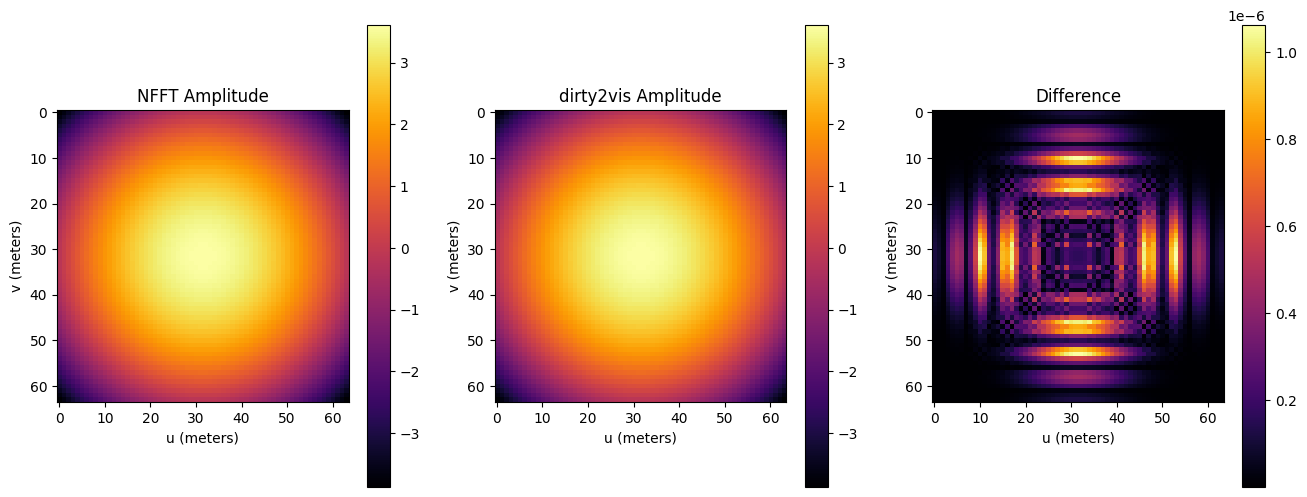

In [7]:
plot_visibility_comparison(vis_nfft, vis_d2v)

In [8]:
def plot_visibility_slice():
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes = axes.flatten()
    im0 = axes[0].plot(baseline_length,np.abs(vis_nfft_1D), '*', label='NUFFT')
    axes[0].set_xlabel("Baseline Length (meters)")
    axes[0].set_ylabel("Visibility Amplitude")
    axes[0].set_title("Visibility Amplitude Comparison")
    im1 = axes[0].plot(baseline_length,np.abs(vis_d2v_1D), label='DUC')
    axes[0].legend()
    im2 = axes[1].plot(baseline_length,np.log10(np.abs(vis_nfft_1D - vis_d2v_1D.flatten())), label='NUFFT - DUC')
    axes[1].set_xlabel("Baseline Length (meters)")
    axes[1].set_ylabel("Log10 Absolute Difference")
    axes[1].set_title("Difference")
    plt.show()

### Plot: NUFFT vs Dirty2Vis Comparison (Slice - 1D)
This function compares the amplitude of the visibilities computed using NUFFT and `dirty2vis`.

It displays three subplots:
- **NFFT Amplitude:** Log-scaled amplitude of NUFFT visibilities.
- **dirty2vis Amplitude:** Log-scaled amplitude of dirty2vis visibilities.
- **Difference:** Absolute difference between the two methods.


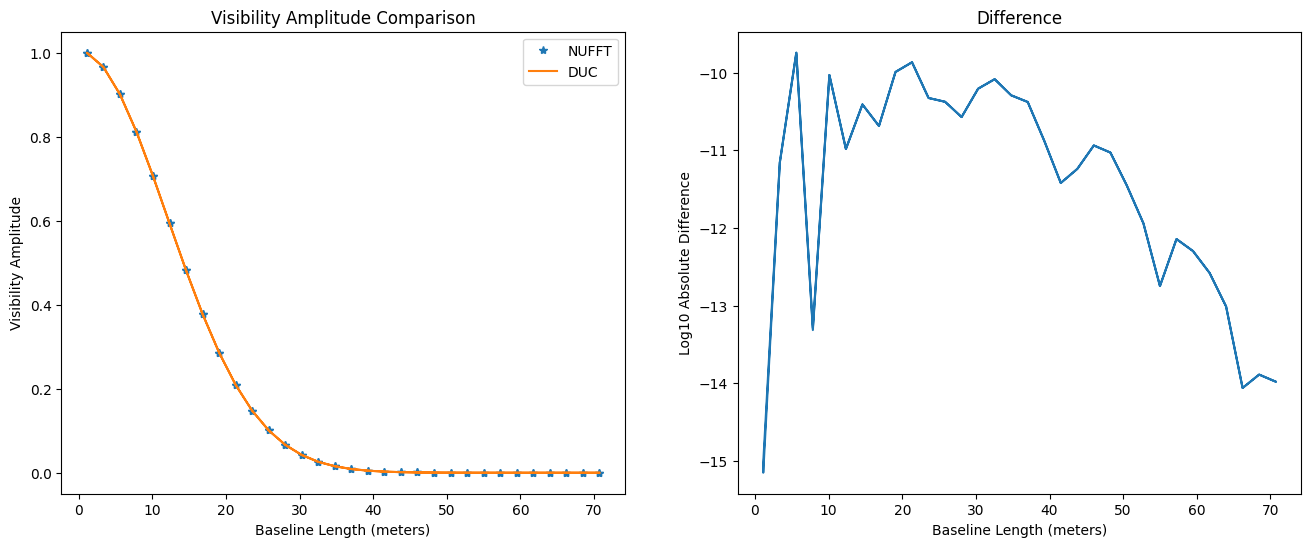

In [9]:
plot_visibility_slice()